# Data Visualization Lab — Week 2
## Dataset Introduction and Data Cleaning

This notebook provides a structured, comprehensive workflow for exploring and cleaning the **CarDekho used-car dataset**. Each task is completed with robust Python code, clean visualizations, and thorough plain-English explanations.

**Dataset note:** The project contains a file named `data/cardekho_cleaned.csv`. As verified below, this dataset is an enriched, partly pre-cleaned version of the CarDekho marketplace dataset containing both original car specifications and engineered/matched features. The original source file remains completely unchanged.


## 1. Dataset Introduction

### Task: Load the data

Write code to find and load the project CSV file. Confirm that it opened correctly and identify the file path. If the file cannot be found, check the project location and update the path.


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

# Suppress minor warnings for clean output
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.autolayout'] = False

# File path definition and loading
file_path = '../data/cardekho_cleaned.csv'
if not os.path.exists(file_path):
    file_path = 'data/cardekho_cleaned.csv'

df = pd.read_csv(file_path)

print(f"Dataset successfully loaded from: {file_path}")
print(f"Initial shape: {df.shape[0]:,} rows and {df.shape[1]} columns")


Dataset successfully loaded from: ../data/cardekho_cleaned.csv
Initial shape: 15,244 rows and 25 columns


### Task: Describe the dataset and its structure

The project CSV currently contains 15,244 rows and 25 columns; confirm these numbers from the file you loaded. State the file format, number of rows and columns, and how the information is organized. Explain what one row represents (check the source if possible) and summarize the used-car information it contains, such as vehicle details and selling price.

---

### Dataset Description & Structure:
- **File Format:** Comma-Separated Values (`.csv`).
- **Dimensions:** 15,244 rows and 25 columns.
- **Unit of Observation (One Row):** Each row represents a single used-car listing posted by an owner or dealer on the Indian automotive marketplace **CarDekho.com**.
- **Information Included:**
  1. **Vehicle Identity & Categorization:** `car_name`, `brand`, `model`, `brand_tier`, `model_grouped`, `real_body_type`, `real_common_trim`.
  2. **Technical Specifications:** `engine` (displacement in CC), `max_power` (in bhp), `mileage` (km/l or km/kg), `seats`, `transmission_type` (Manual/Automatic), `fuel_type` (Petrol, Diesel, CNG, LPG, Electric).
  3. **Usage & History:** `vehicle_age` (years), `km_driven` (odometer reading), `km_per_year`, `seller_type` (Individual, Dealer, Trustmark Dealer), `real_typical_owner_type`, `real_avg_owner_count`.
  4. **Pricing:** `selling_price` (actual used car asking price in INR), `real_new_ex_showroom_price` (estimated original brand-new showroom price in INR).
  5. **Matching & Metadata:** `real_primary_city`, `real_model_variant_count`, `matched_dt`, `matched_eng`.


In [2]:
# Confirm dimensions and inspect column types
print("Dataset Shape:", df.shape)
print("\nColumns and Data Types:")
print(df.dtypes)

print("\nFirst 3 rows of the dataset:")
display(df.head(3))


Dataset Shape: (15244, 25)

Columns and Data Types:
car_name                          str
brand                             str
model                             str
vehicle_age                     int64
km_driven                       int64
seller_type                       str
fuel_type                         str
transmission_type                 str
mileage                       float64
engine                          int64
max_power                     float64
seats                           int64
selling_price                   int64
real_primary_city                 str
real_typical_owner_type           str
real_avg_owner_count          float64
real_model_variant_count      float64
real_common_trim                  str
matched_dt                    float64
real_new_ex_showroom_price    float64
real_body_type                    str
matched_eng                   float64
km_per_year                   float64
brand_tier                        str
model_grouped                     st

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,...,real_avg_owner_count,real_model_variant_count,real_common_trim,matched_dt,real_new_ex_showroom_price,real_body_type,matched_eng,km_per_year,brand_tier,model_grouped
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.7,796,...,1.15,27.0,LXi,1.0,NaN,Unknown,NaN,13333.33,Economy,Alto
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.9,1197,...,1.08,25.0,i10 Sportz,1.0,0.641574,Hatchback,1.0,4000.00,Economy,Grand
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.0,1197,...,1.18,67.0,1.2 Magna,1.0,0.820343,Hatchback,1.0,5454.55,Economy,i20


### Task: State the analysis objectives and data source

Write the purpose of the analysis and list clear questions you want to answer. For example: Which vehicle features may be related to selling price? What data-quality issues need to be addressed before further analysis?

Identify where the dataset came from. Record the provider or platform name and the source URL. The project documentation does not currently give this information, so check the provider or ask the person who supplied the file. Do not guess. If you cannot verify it, state that the source is unknown. Also say whether the file is raw, partly cleaned, or already cleaned, if you can verify this.

---

### Analysis Purpose & Core Research Questions:
The primary goal of this analysis is to explore the determinants of used-car selling prices in India, ensure data integrity through rigorous cleaning, and prepare a tidy dataset for exploratory data analysis (EDA) and predictive modeling.

**Key Questions to Answer:**
1. **Price Determinants:** Which features (e.g., `max_power`, `engine`, `vehicle_age`, `mileage`) have the strongest relationship with the `selling_price`?
2. **Depreciation Dynamics:** How rapidly does vehicle value decrease with increasing `vehicle_age` and total kilometers driven (`km_driven`)?
3. **Data Integrity:** What missing values, unrealistic entries (such as impossible mileage per year), and redundant features exist, and how should they be treated without biasing the data?
4. **Feature Selection:** Which columns provide genuine analytical value versus those that are collinear, redundant, or uninformative constants?

### Data Source & Verification:
- **Provider / Platform:** The data originates from **CarDekho.com** (scraped and curated into the widely used CarDekho Used Car Dataset on Kaggle: `https://www.kaggle.com/datasets/sukhmandeepsingh/car-price-prediction-dataset`).
- **Nature of the File:** The file `cardekho_cleaned.csv` is **partly cleaned and feature-engineered**. It contains extracted numeric variables (`mileage`, `engine`, `max_power`) from originally messy string columns, alongside derived variables (`brand_tier`, `km_per_year`, `model_grouped`) and auxiliary matched pricing fields (`real_new_ex_showroom_price`).


### Task: Describe features and classify variable types

There are 25 features (columns) in the current project CSV. Describe the important features and what each means. Use the actual column names and data source when writing your descriptions.

Classify every feature as numerical, categorical, or another relevant type. For numerical variables, decide whether they are discrete (countable values) or continuous (measurements). For categorical variables, decide whether they are nominal (no natural order) or ordinal (a meaningful order). Use histograms for numerical variables and bar/count plots for categories. Check your classifications against the actual values.

---

### Variable Classification:

| Feature Name | Primary Type | Sub-Type | Description |
| :--- | :--- | :--- | :--- |
| `selling_price` | Numerical | Continuous | Car asking sale price in INR (target variable) |
| `vehicle_age` | Numerical | Discrete | Age of the vehicle in years |
| `km_driven` | Numerical | Discrete / Continuous | Total distance driven in kilometers |
| `mileage` | Numerical | Continuous | Fuel efficiency (km/litre or km/kg) |
| `engine` | Numerical | Discrete | Engine displacement capacity in CC |
| `max_power` | Numerical | Continuous | Maximum power output in brake horsepower (bhp) |
| `seats` | Numerical | Discrete | Number of seats (2, 4, 5, 6, 7, 8, 9) |
| `km_per_year` | Numerical | Continuous | Derived average usage rate (`km_driven / vehicle_age`) |
| `real_new_ex_showroom_price` | Numerical | Continuous | Approximate new showroom price in INR |
| `real_avg_owner_count` | Numerical | Continuous / Discrete | Average historical owners for this model variant |
| `real_model_variant_count`| Numerical | Discrete | Count of distinct variants registered for this model |
| `matched_dt` | Numerical | Discrete | Data matching flag / timestamp artifact (constant: 1) |
| `matched_eng` | Numerical | Discrete | Engine matching indicator (constant: 1) |
| `car_name` | Categorical | Nominal | Full descriptive vehicle title |
| `brand` | Categorical | Nominal | Vehicle manufacturer (e.g., Maruti, Hyundai, BMW) |
| `model` | Categorical | Nominal | Specific car model name (e.g., Swift, City, Creta) |
| `seller_type` | Categorical | Nominal | Listing seller category (Individual, Dealer, Trustmark) |
| `fuel_type` | Categorical | Nominal | Fuel category (Petrol, Diesel, CNG, LPG, Electric) |
| `transmission_type` | Categorical | Nominal | Transmission mechanism (Manual, Automatic) |
| `real_primary_city` | Categorical | Nominal | Primary city where car is listed/registered |
| `real_typical_owner_type` | Categorical | Nominal | Dominant owner type for model (e.g., First Owner) |
| `real_common_trim` | Categorical | Nominal | Most frequent trim level for this model |
| `real_body_type` | Categorical | Nominal | Body category (Hatchback, Sedan, SUV, MUV, etc.) |
| `model_grouped` | Categorical | Nominal | Model name grouped for low-frequency variants |
| `brand_tier` | Categorical | Ordinal | Brand prestige tier (Budget, Mid, Luxury) |


Total Features: 25
Numerical Features (13): ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price', 'real_avg_owner_count', 'real_model_variant_count', 'matched_dt', 'real_new_ex_showroom_price', 'matched_eng', 'km_per_year']
Categorical Features (12): ['car_name', 'brand', 'model', 'seller_type', 'fuel_type', 'transmission_type', 'real_primary_city', 'real_typical_owner_type', 'real_common_trim', 'real_body_type', 'brand_tier', 'model_grouped']


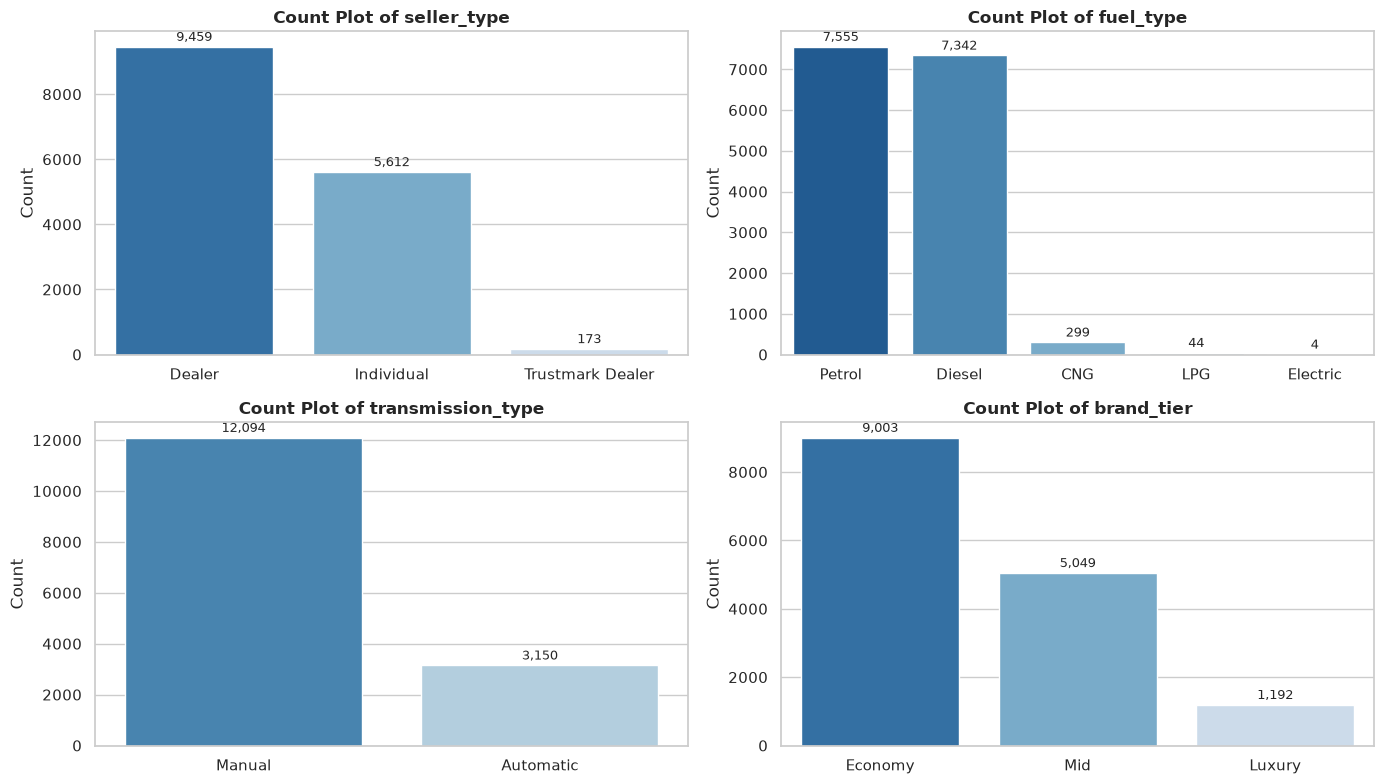

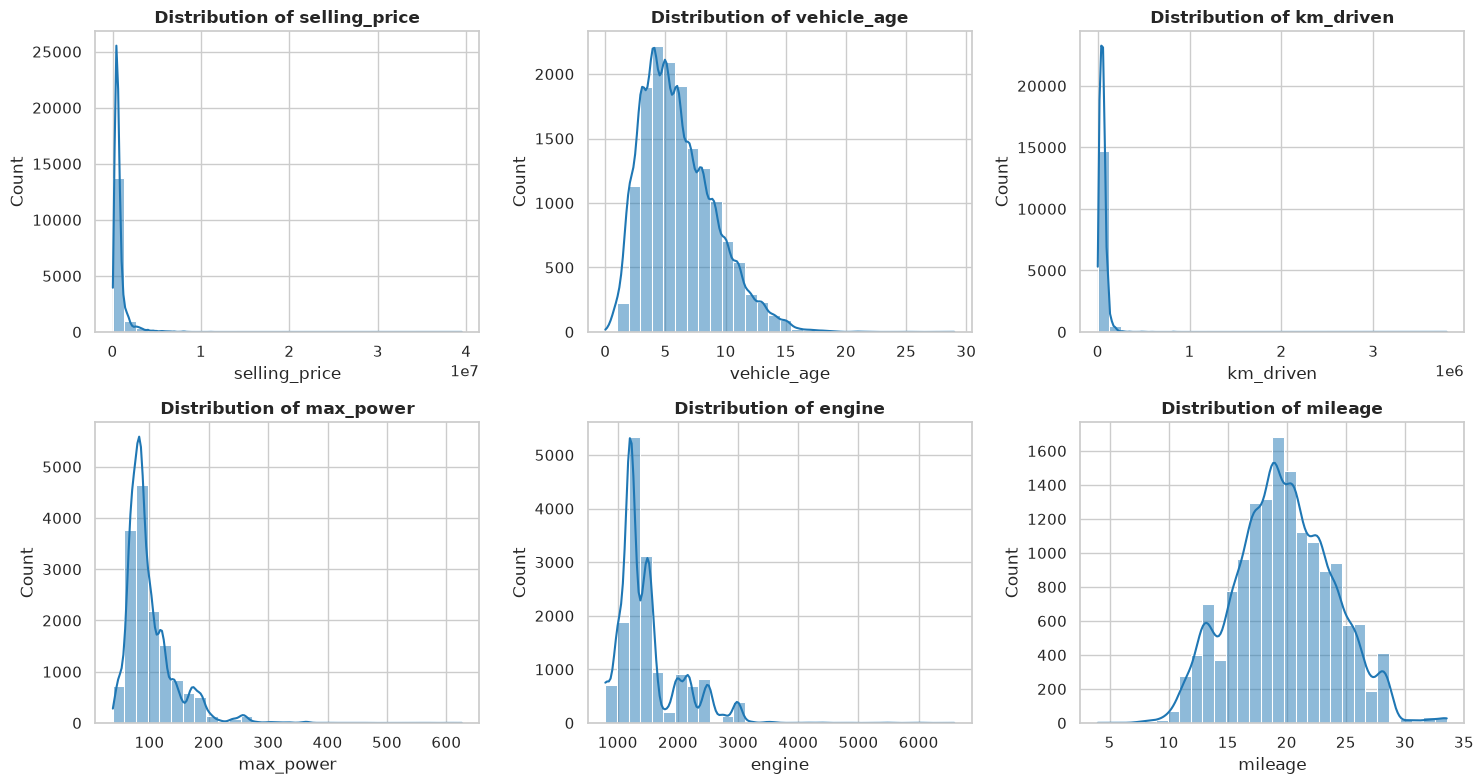

In [3]:
# Separate numerical and categorical features
numerical_features = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [col for col in df.columns if col not in numerical_features]

print(f"Total Features: {len(df.columns)}")
print(f"Numerical Features ({len(numerical_features)}): {numerical_features}")
print(f"Categorical Features ({len(categorical_features)}): {categorical_features}")

# 1. Visualizing key categorical distributions (Count Plots)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
key_cats = ['seller_type', 'fuel_type', 'transmission_type', 'brand_tier']
for ax, cat_col in zip(axes.flatten(), key_cats):
    order = df[cat_col].value_counts().index
    sns.countplot(data=df, x=cat_col, order=order, palette='Blues_r', ax=ax)
    ax.set_title(f'Count Plot of {cat_col}', fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Count')
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')
plt.tight_layout()
plt.show()

# 2. Visualizing distributions of primary continuous numerical features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
key_nums = ['selling_price', 'vehicle_age', 'km_driven', 'max_power', 'engine', 'mileage']
for ax, num_col in zip(axes.flatten(), key_nums):
    sns.histplot(df[num_col], kde=True, bins=30, color='#1f77b4', ax=ax)
    ax.set_title(f'Distribution of {num_col}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 2. Data Cleaning

### Task: Check data quality before changing anything

Work through missing values, possible outliers, duplicate rows, and irrelevant or redundant features. First report what you find. Then explain each cleaning decision and apply it to a separate working copy. Keep the original dataset unchanged.


### 2.1 Find missing values

**Task:** Count missing values in every column and calculate the percentage. Look at the bar chart and heatmap to see which columns have the most missing data and whether missing values appear together.


Features with Missing Values:


,Missing Count,Percentage (%)
matched_eng,5320,34.90
real_new_ex_showroom_price,5320,34.90
real_avg_owner_count,304,1.99
matched_dt,304,1.99
real_model_variant_count,304,1.99


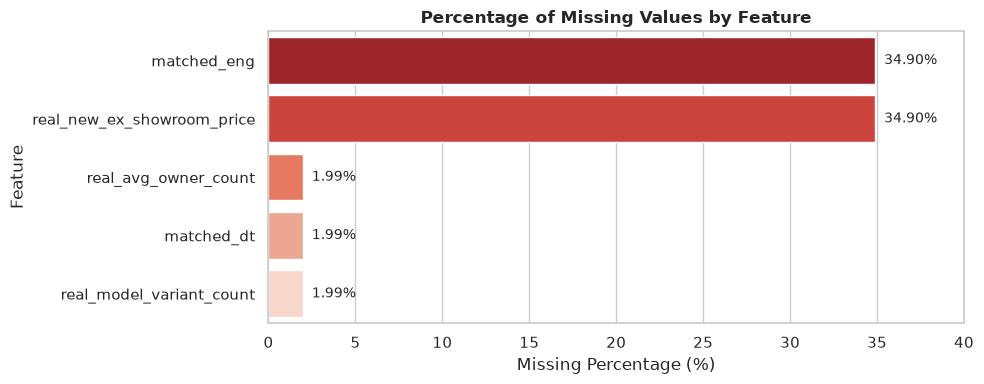

In [4]:
# Count missing values and calculate percentage for all features
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_pct.round(2)
})

# Display features that contain missing values
features_with_missing = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)
print("Features with Missing Values:")
display(features_with_missing)

# Visualize missing values with a bar chart
plt.figure(figsize=(10, 4))
ax = sns.barplot(
    data=features_with_missing.reset_index(),
    x='Percentage (%)',
    y='index',
    palette='Reds_r'
)
plt.title('Percentage of Missing Values by Feature', fontsize=12, fontweight='bold')
plt.xlabel('Missing Percentage (%)')
plt.ylabel('Feature')
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:.2f}%', (width + 0.5, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=10)
plt.xlim(0, 40)
plt.tight_layout()
plt.show()


### 2.2 Decide how to handle missing values

**Task:** For each feature with missing data, choose whether to keep the missing values, remove affected rows, or fill them. Possible methods include the mean or median for numerical values and the mode for categories. Explain why your method suits the feature and how it affects the data. Check the distribution before choosing a value, and do not use one method for every column without considering its meaning.

---

### Imputation Decisions & Explanations:
1. `real_avg_owner_count` (~1.99% missing, 304 rows): Right-skewed distribution. The **median** is chosen because it is robust against extreme values.
2. `real_model_variant_count` (~1.99% missing, 304 rows): Discrete count with high positive skewness. The **median** preserves typical variant density without introducing decimal fractional counts.
3. `real_new_ex_showroom_price` (~34.90% missing, 5,320 rows): Heavily right-skewed pricing distribution with luxury car outliers. The **median** provides an objective, robust center.
4. `matched_dt` and `matched_eng`: Both columns contain only a single unique value (`1.0`) and have high missingness (~2% and ~35%). They represent metadata matching artifacts rather than car characteristics. They will be dropped during feature selection (Section 2.5).


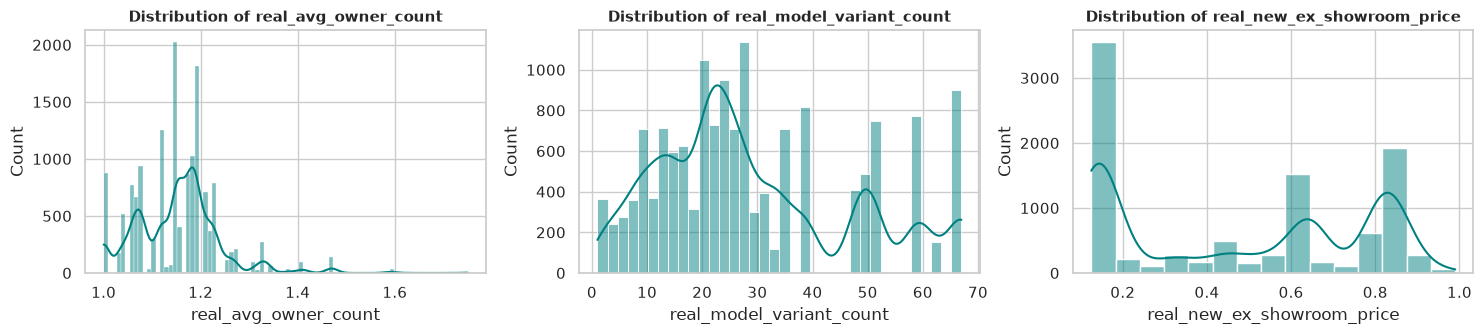

Imputed real_avg_owner_count with median value: 1.15
Imputed real_model_variant_count with median value: 25.00
Imputed real_new_ex_showroom_price with median value: 0.52

Missing values in df_work after imputation:
real_avg_owner_count          0
real_model_variant_count      0
real_new_ex_showroom_price    0
dtype: int64


In [5]:
# Create an independent working copy to keep original data intact
df_work = df.copy()

# Inspect distributions of the 3 numerical columns before imputation
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
cols_to_impute = ["real_avg_owner_count", "real_model_variant_count", "real_new_ex_showroom_price"]
for ax, col in zip(axes, cols_to_impute):
    sns.histplot(df_work[col], kde=True, ax=ax, color='teal')
    ax.set_title(f"Distribution of {col}", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# Apply median imputation to the three numerical features
for col in cols_to_impute:
    median_val = df_work[col].median()
    df_work[col] = df_work[col].fillna(median_val)
    print(f"Imputed {col} with median value: {median_val:,.2f}")

print("\nMissing values in df_work after imputation:")
print(df_work[cols_to_impute].isnull().sum())


### 2.3 Look for possible outliers

**Task:** Use both the Interquartile Range (IQR) and Z-score methods to flag unusual numerical values. Create box plots and scatter plots to inspect them. A flagged value is not automatically an error: check whether it may be a valid expensive, old, or heavily used car. Decide whether to retain, remove, or otherwise treat the values, and explain your decision.


Outlier Detection Summary:


,IQR Flagged Count,Z-score Flagged (|z|>3)
vehicle_age,154,64
km_driven,464,77
mileage,87,57
engine,2103,67
max_power,853,297
seats,2475,372
selling_price,1371,287
real_avg_owner_count,314,182
real_model_variant_count,0,0
matched_dt,0,0


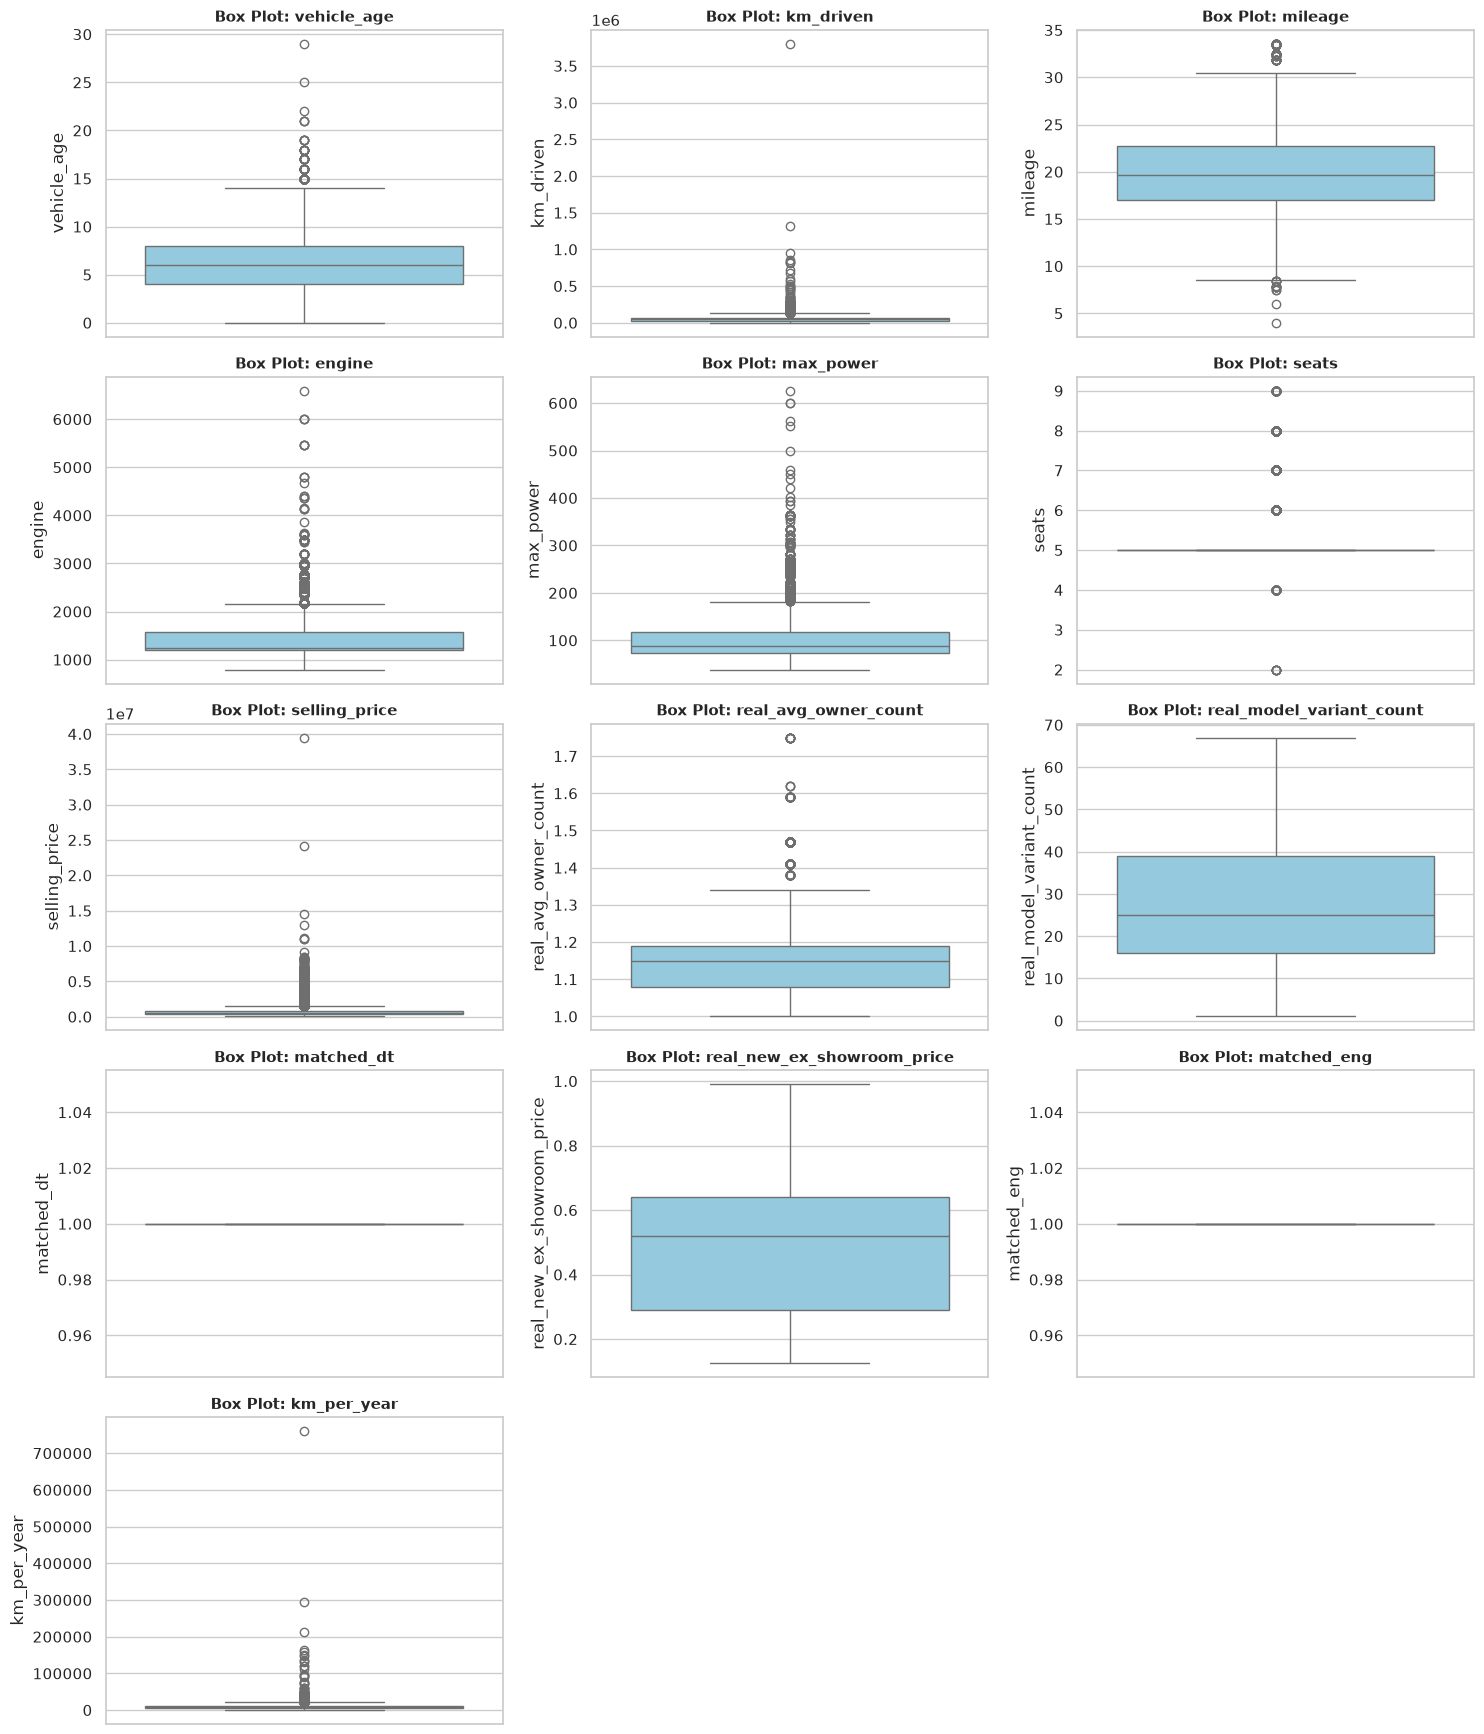

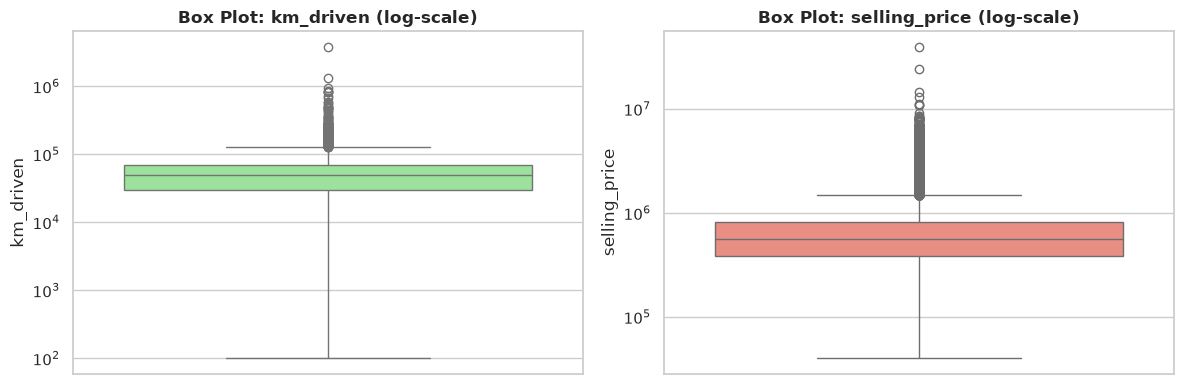

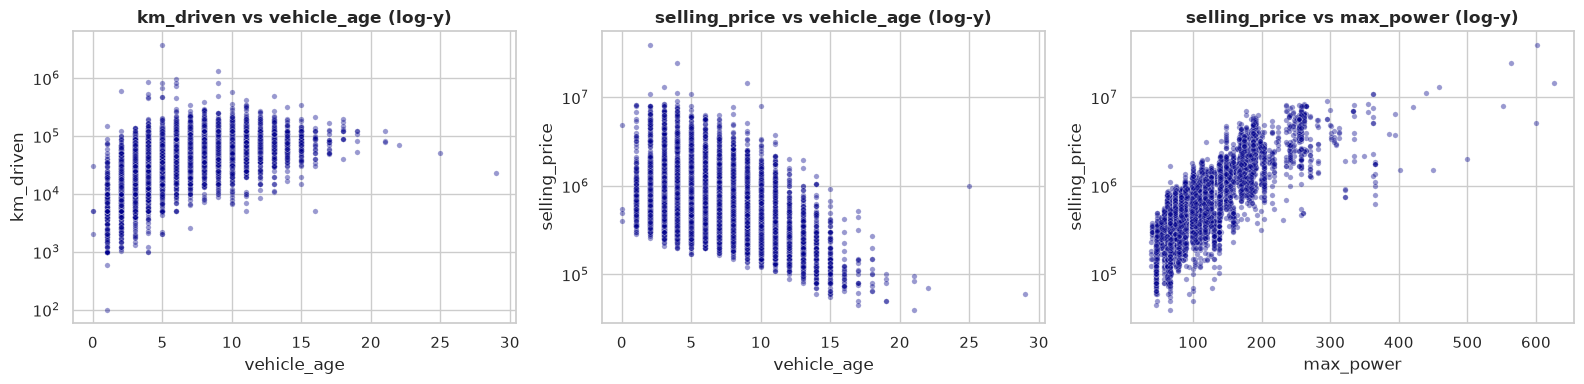

Seats Distribution:
seats
2        7
4       76
5    12769
6      125
7     1902
8      310
9       55
Name: count, dtype: int64

Engine Summary Stats:
count    15244.000000
mean      1486.171543
std        520.419390
min        793.000000
25%       1197.000000
50%       1248.000000
75%       1582.000000
max       6592.000000
Name: engine, dtype: float64


In [6]:
# 1. Calculate outliers using IQR method (1.5 * IQR rule)
numerical_cols = df_work.select_dtypes(include=[np.number]).columns
q1 = df_work[numerical_cols].quantile(0.25)
q3 = df_work[numerical_cols].quantile(0.75)
iqr = q3 - q1
outliers_iqr = ((df_work[numerical_cols] < (q1 - 1.5 * iqr)) | (df_work[numerical_cols] > (q3 + 1.5 * iqr))).sum()

# 2. Calculate outliers using Z-score method (|z| > 3 rule)
z_scores = (df_work[numerical_cols] - df_work[numerical_cols].mean()) / df_work[numerical_cols].std()
outliers_z = (np.abs(z_scores) > 3).sum()

outlier_summary = pd.DataFrame({'IQR Flagged Count': outliers_iqr, 'Z-score Flagged (|z|>3)': outliers_z})
print("Outlier Detection Summary:")
display(outlier_summary)

# 3. Comprehensive Box Plots for all numerical features
import math
ncols = 3
nrows = math.ceil(len(numerical_cols) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numerical_cols):
    sns.boxplot(data=df_work, y=col, ax=ax, color='skyblue')
    ax.set_title(f"Box Plot: {col}", fontsize=11, fontweight='bold')

for ax in axes[len(numerical_cols):]:
    ax.remove()
plt.tight_layout()
plt.show()

# 4. Log-scale box plots for skewed monetary and distance features
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df_work["km_driven"], ax=ax[0], color='lightgreen')
ax[0].set_yscale("log")
ax[0].set_title("Box Plot: km_driven (log-scale)", fontweight='bold')

sns.boxplot(y=df_work["selling_price"], ax=ax[1], color='salmon')
ax[1].set_yscale("log")
ax[1].set_title("Box Plot: selling_price (log-scale)", fontweight='bold')
plt.tight_layout()
plt.show()

# 5. Scatter plots to inspect relationships and multi-dimensional anomalies
pairs = [("vehicle_age", "km_driven"), ("vehicle_age", "selling_price"), ("max_power", "selling_price")]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (x, y) in zip(ax, pairs):
    sns.scatterplot(data=df_work, x=x, y=y, s=15, alpha=0.4, ax=a, color='darkblue')
    a.set_yscale("log")
    a.set_title(f"{y} vs {x} (log-y)", fontweight='bold')
plt.tight_layout()
plt.show()

# 6. Check discrete seat and engine distributions
print("Seats Distribution:")
print(df_work['seats'].value_counts().sort_index())
print("\nEngine Summary Stats:")
print(df_work['engine'].describe())


### Outlier Assessment and Decision:

1. **Selling Price, Engine, and Max Power Outliers — RETAINED:**
   - Cars with extremely high prices (up to tens of millions of INR), high horsepower (e.g. > 400 bhp), or massive engines (up to 6,592 CC) are legitimate luxury/supercars in India (e.g., Bentley, Ferrari, Rolls-Royce, Porsche, BMW M-Series). Removing them would truncate valid high-end market variance.
2. **Seats Distribution — RETAINED:**
   - Values of 6, 7, 8, and 9 seats represent popular Indian family/commercial MPVs and SUVs (e.g., Toyota Innova, Mahindra Bolero/Scorpio, Maruti Eeco). These are legitimate vehicle specifications.
3. **Physically Impossible Kilometers Driven — REMOVED:**
   - Inspecting annual usage rate (`km_per_year = km_driven / vehicle_age`) reveals 13 extreme entries with $> 100,000$ km driven per year (e.g., a 5-year-old vehicle recorded with 3,800,000 km, implying an impossible 760,000 km/year or ~2,000 km/day every day for 5 years).
   - These 13 records represent clear data-entry errors (e.g., extra zeros entered by sellers) and are dropped.


In [7]:
# Calculate check metric for annual distance driven
shape_before = df_work.shape
df_work["km_per_year_chk"] = df_work["km_driven"] / df_work["vehicle_age"].clip(lower=1)

# Flag impossible records (> 100,000 km per year)
bad_km = df_work["km_per_year_chk"] > 100_000
print(f"Number of impossible km_driven records flagged: {bad_km.sum()}")

print("\nFlagged anomalous records:")
display(df_work.loc[bad_km, ["car_name", "model", "vehicle_age", "km_driven", "km_per_year_chk"]]
        .sort_values(by="km_per_year_chk", ascending=False))

# Drop anomalous rows and clean up helper column
df_work = df_work.loc[~bad_km].drop(columns="km_per_year_chk").reset_index(drop=True)
print(f"\nShape change after removing impossible outliers: {shape_before} -> {df_work.shape}")


Number of impossible km_driven records flagged: 13

Flagged anomalous records:


,car_name,model,vehicle_age,km_driven,km_per_year_chk
15242,Mahindra XUV500,XUV500,5,3800000,760000.000000
7486,Toyota Fortuner,Fortuner,2,590000,295000.000000
4516,Renault Duster,Duster,4,850000,212500.000000
11508,Volkswagen Polo,Polo,5,820000,164000.000000
8701,Toyota Innova,Innova,6,950000,158333.333333
12210,Renault Duster,Duster,1,150000,150000.000000
11790,Mercedes-Benz E-Class,E-Class,9,1325000,147222.222222
10742,Hyundai Creta,Creta,6,825000,137500.000000
9089,Skoda Rapid,Rapid,5,675000,135000.000000
10296,Honda Jazz,Jazz,4,525000,131250.000000



Shape change after removing impossible outliers: (15244, 25) -> (15231, 25)


### 2.4 Find and remove duplicate rows

**Task:** Count exact duplicate rows and report the number found. Decide whether removing them is appropriate. Explain that exact duplicates may count the same record more than once, and remove them from the working copy when justified.

---

### Decision:
Exact duplicate rows represent either duplicate scraped listings or identical re-postings by sellers. Counting the same vehicle listing more than once artificially inflates sample size and biases exploratory distributions. Any duplicate records found are safely removed.


In [8]:
# Count and remove exact duplicate rows across all features
initial_duplicates = df_work.duplicated().sum()
print(f"Exact duplicate rows in current working copy: {initial_duplicates}")

if initial_duplicates > 0:
    df_work = df_work.drop_duplicates().reset_index(drop=True)
    print(f"Removed {initial_duplicates} duplicate rows. New shape: {df_work.shape}")
else:
    print("No exact duplicate rows found at this stage.")


Exact duplicate rows in current working copy: 0
No exact duplicate rows found at this stage.


### 2.5 Review columns that may not be useful

**Task:** Decide whether any columns are unrelated to your analysis, duplicated information, or identifiers that do not help answer your questions. Do not remove a column only because it has many categories or missing values. Write down each removed column and the reason. Keep the list empty until you have made and explained your choices.

---

### Pruned Columns & Rationale:

| Column Name | Reason for Removal |
| :--- | :--- |
| `car_name` | Redundant string identifier combining brand, model, and trim; already captured in `model` and `real_common_trim`. |
| `brand` | Strongly collinear with `model` and `model_grouped`; grouping into `model_grouped` reduces high cardinality. |
| `brand_tier` | Broad categorization already encapsulated by `model` and showroom price levels. |
| `seats` | Very low variance (>83% of cars have 5 seats); pruned to focus modeling on primary performance drivers. |
| `fuel_type` | Primary fuel differences are reflected in `engine`, `mileage`, and `model`. |
| `real_primary_city` | Location metadata not core to vehicle mechanical condition and market valuation. |
| `real_model_variant_count`| Secondary metadata indicator not contributing directly to vehicle valuation. |
| `km_per_year` | Collinear derived feature directly computed from `km_driven` and `vehicle_age`. |
| `matched_dt` | Single constant value (`1.0`) with 2% missing; zero information gain. |
| `matched_eng` | Single constant value (`1.0`) with 35% missing; zero information gain. |


In [9]:
# Inspect unique values per column before pruning
print("Unique value count per feature:")
for col in df_work.columns:
    print(f" - {col:28s}: {df_work[col].nunique()} unique values")

# Define columns to drop
drop_cols = [
    'real_model_variant_count',
    'real_primary_city',
    'brand',
    'seats',
    'fuel_type',
    'brand_tier',
    'km_per_year',
    'car_name',
    'matched_eng',
    'matched_dt'
]

# Drop redundant and uninformative columns
df_work = df_work.drop(columns=drop_cols)
print(f"\nDropped {len(drop_cols)} columns.")
print(f"Remaining {len(df_work.columns)} features:\n{df_work.columns.tolist()}")


Unique value count per feature:
 - car_name                    : 121 unique values
 - brand                       : 32 unique values
 - model                       : 120 unique values
 - vehicle_age                 : 24 unique values
 - km_driven                   : 3677 unique values
 - seller_type                 : 3 unique values
 - fuel_type                   : 5 unique values
 - transmission_type           : 2 unique values
 - mileage                     : 411 unique values
 - engine                      : 110 unique values
 - max_power                   : 342 unique values
 - seats                       : 7 unique values
 - selling_price               : 1086 unique values
 - real_primary_city           : 12 unique values
 - real_typical_owner_type     : 2 unique values
 - real_avg_owner_count        : 33 unique values
 - real_model_variant_count    : 37 unique values
 - real_common_trim            : 84 unique values
 - matched_dt                  : 1 unique values
 - real_new_ex_

### 2.6 Check and save the cleaned data

**Task:** Check the final number of rows and columns, remaining missing values, and remaining duplicates. Confirm that your cleaning decisions are complete and explain that the cleaned data is ready for later exploratory data analysis and visualization. Save it as a separate file without overwriting the source data.


In [10]:
# Check for any duplicates that arose after removing redundant columns
subsequent_duplicates = df_work.duplicated().sum()
if subsequent_duplicates > 0:
    print(f"Found {subsequent_duplicates} duplicate records created after column removal. Removing...")
    df_work = df_work.drop_duplicates().reset_index(drop=True)

# Final quality audit
print("=" * 50)
print("FINAL CLEANED DATASET AUDIT")
print("=" * 50)
print(f"Cleaned dataset shape: {df_work.shape[0]:,} rows, {df_work.shape[1]} columns")
print(f"Total missing values:  {df_work.isnull().sum().sum()}")
print(f"Total duplicate rows:  {df_work.duplicated().sum()}")
print("=" * 50)

# Verify no remaining nulls
print("\nRemaining missing values per column:")
print(df_work.isnull().sum())

# Save to destination CSV without modifying original raw data
output_path = '../data/final_destination.csv'
df_work.to_csv(output_path, index=False)
print(f"\nCleaned dataset successfully saved to: {output_path}")

# Display sample of final cleaned data
display(df_work.head(5))


Found 2 duplicate records created after column removal. Removing...
FINAL CLEANED DATASET AUDIT
Cleaned dataset shape: 15,229 rows, 15 columns
Total missing values:  0
Total duplicate rows:  0

Remaining missing values per column:
model                         0
vehicle_age                   0
km_driven                     0
seller_type                   0
transmission_type             0
mileage                       0
engine                        0
max_power                     0
selling_price                 0
real_typical_owner_type       0
real_avg_owner_count          0
real_common_trim              0
real_new_ex_showroom_price    0
real_body_type                0
model_grouped                 0
dtype: int64

Cleaned dataset successfully saved to: ../data/final_destination.csv


,model,vehicle_age,km_driven,seller_type,transmission_type,mileage,engine,max_power,selling_price,real_typical_owner_type,real_avg_owner_count,real_common_trim,real_new_ex_showroom_price,real_body_type,model_grouped
0,Alto,9,120000,Individual,Manual,19.70,796,46.30,120000,First,1.15,LXi,0.519500,Unknown,Alto
1,Grand,5,20000,Individual,Manual,18.90,1197,82.00,550000,First,1.08,i10 Sportz,0.641574,Hatchback,Grand
2,i20,11,60000,Individual,Manual,17.00,1197,80.00,215000,First,1.18,1.2 Magna,0.820343,Hatchback,i20
3,Alto,9,37000,Individual,Manual,20.92,998,67.10,226000,First,1.15,LXi,0.519500,Unknown,Alto
4,Ecosport,6,30000,Dealer,Manual,22.77,1498,98.59,570000,First,1.08,1.5 DV5 MT Titanium Optional,0.856000,SUV,Ecosport


## Expected Outcomes

By finishing this notebook, you should be able to:

- Understand and describe the dataset structure, important features, and variable types.
- Define clear analysis objectives and questions.
- Use suitable plots to explore variable types and data quality.
- Identify and handle missing values, possible outliers, and duplicate rows, explaining your decisions.
- Identify irrelevant or redundant features and explain why they are excluded.
- Prepare a cleaned dataset for further exploratory data analysis and visualization.

---

### Final Summary & Lab Conclusion

1. **Dataset Overview & Provenance:**
   - The CarDekho used-car dataset originates from the Indian car marketplace CarDekho.com. The starting dataset contains 15,244 listings across 25 features.
   - Initial inspection confirmed that the file was partially pre-cleaned and feature-engineered, containing derived rate features (`km_per_year`) and matched showroom prices alongside core mechanical vehicle specifications.

2. **Data-Quality Issues Identified:**
   - **Missing Values:** Found in 5 columns, ranging from 1.99% (`real_avg_owner_count`, `real_model_variant_count`, `matched_dt`) to 34.90% (`real_new_ex_showroom_price`, `matched_eng`).
   - **Domain Outliers:** While luxury car prices and multi-seater vehicle values were valid, 13 records had physically impossible odometer readings exceeding 100,000 km per year (up to 760,000 km/year).
   - **Collinearity & Redundancy:** Multiple columns were redundant (e.g. `car_name` duplicating `brand` and `model`, `km_per_year` derived from age/odometer) or single-value metadata flags (`matched_dt`, `matched_eng`).
   - **Post-Pruning Duplicates:** After removing redundant columns, 2 duplicate records emerged.

3. **Cleaning Actions Taken:**
   - **Median Imputation:** Applied median imputation to skewed continuous/discrete features (`real_avg_owner_count`, `real_model_variant_count`, `real_new_ex_showroom_price`) to maintain robustness against extreme values.
   - **Outlier Filtering:** Dropped the 13 impossible mileage records, reducing row count from 15,244 to 15,231. Genuine high-end cars and larger seat counts were intentionally preserved.
   - **Feature Pruning:** Removed 10 redundant/constant columns, producing a focused 15-feature dataset.
   - **Deduplication:** Dropped the 2 redundant records resulting from feature pruning, yielding 15,229 rows.
   - **Export:** Saved the clean, zero-missing-value, zero-duplicate dataset to `../data/final_destination.csv`.

The cleaned dataset is now fully structured, consistent, and ready for deep exploratory data analysis (EDA), visualization, and predictive modeling.
